# Customer Churn Analysis

**IBM Telco sample data · Python · exploratory and statistical analysis**

This release examines recorded churn across customer groups and quantifies selected unadjusted associations. Data preparation, exploration, and statistical comparisons are complete. Multivariable modeling and predictive evaluation are planned extensions; no predictive performance is claimed.

**Key findings — training sample (5,634 customers):**

- Recorded churn is 26.54%. It is 42.75% for month-to-month contracts, 11.08% for one-year contracts, and 2.87% for two-year contracts.
- Month-to-month churn remains highest within each displayed tenure band.
- Churned customers have 19.23 months shorter mean tenure (95% Welch CI for the difference: −20.47 to −17.99 months).

These findings describe fictional observational data. They identify questions for investigation, not proven retention interventions.

## Contents

1. [Project overview](#1-project-overview-and-analytical-questions)
2. [Data source and variables](#2-data-source-and-understanding)
3. [Data quality](#3-data-quality-assessment-and-preparation)
4. [Analysis design](#4-analysis-and-validation-design)
5. [Exploratory analysis](#5-exploratory-data-analysis)
6. [Statistical comparisons](#6-selected-statistical-comparisons)
7. [Conclusions and next steps](#7-current-conclusions-limitations-and-next-steps)

**Run instructions:** See the repository README for dependencies and data download. Run this notebook from the `notebooks/` directory, then restart the kernel and run all cells. The CSV path is relative to that directory.

## 1. Project overview and analytical questions

### 1.1 Business context and current objective

Understanding which customer groups have higher recorded churn can help an analytics team prioritize retention research. This project examines customer characteristics, services, contracts, and billing attributes in IBM's fictional Telco sample.

The current release delivers a documented data-quality assessment, exploratory analysis, and selected statistical comparisons. Its business contribution is to identify patterns worth investigating and explain the limits of the evidence.

### 1.2 Research questions

1. **Current release:** How does recorded churn vary across contract, tenure, charges, services, and customer groups? How large are selected unadjusted differences?
2. **Planned:** How do selected associations change after adjustment for other observed variables?
3. **Planned:** How well can logistic regression classify recorded churn on held-out customers relative to a simple baseline?

Contract, tenure, and monthly charges receive particular attention. A test set is reserved before outcome-focused exploration to support the planned predictive extension.

### 1.3 Scope

This is an observational analysis of fictional data, not evidence about a real company. Associations cannot establish the effect of changing contracts, providing support, or implementing other retention measures.

The timing of customer attributes relative to churn is not established, so the planned task is classification of recorded churn status rather than operational forecasting. Prior exploration of this dataset also limits the independence of any future test evaluation.

## 2. Data source and understanding

### 2.1 Data source and scope

The local CSV contains 7,043 customer records and 21 columns. Each row describes one customer; the file is a snapshot rather than repeated observations over time.

- [IBM sample description](https://community.ibm.com/community/user/blogs/steven-macko/2018/11/26/new-base-samples-for-ibm-cognos-analytics-1111): fictional telecom data; churn indicates whether the customer left within the last month.
- [IBM-hosted CSV](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv): reference download, with setup details in `data/README.md`.

The original acquisition date of the local copy is unavailable. No collection year, sampling process, or feature measurement date is inferred from the filename.

### 2.2 Variable dictionary

| Group | Variable | Description | Analytical role |
|---|---|---|---|
| Identifier | `customerID` | Customer identifier. Used to check record uniqueness and excluded from model predictors. | Identifier |
| Customer characteristics | `gender` | Customer gender recorded as `Female` or `Male`. | Categorical |
| Customer characteristics | `SeniorCitizen` | Indicates whether the customer is a senior citizen: `1` = Yes, `0` = No. | Binary categorical |
| Customer characteristics | `Partner` | Indicates whether the customer has a partner: `Yes` or `No`. | Binary categorical |
| Customer characteristics | `Dependents` | Indicates whether the customer has dependents: `Yes` or `No`. | Binary categorical |
| Customer relationship | `tenure` | Number of months the customer has stayed with the company. | Numerical, discrete |
| Customer relationship | `Contract` | Customer's contract term: `Month-to-month`, `One year`, or `Two year`. | Categorical |
| Telephone services | `PhoneService` | Indicates whether the customer subscribes to telephone service: `Yes` or `No`. | Binary categorical |
| Telephone services | `MultipleLines` | Indicates whether the customer has multiple telephone lines: `Yes`, `No`, or `No phone service`. | Categorical |
| Internet services | `InternetService` | Customer's internet service category: `DSL`, `Fiber optic`, or `No`. | Categorical |
| Internet services | `OnlineSecurity` | Indicates whether the customer subscribes to online security: `Yes`, `No`, or `No internet service`. | Categorical |
| Internet services | `OnlineBackup` | Indicates whether the customer subscribes to online backup: `Yes`, `No`, or `No internet service`. | Categorical |
| Internet services | `DeviceProtection` | Indicates whether the customer subscribes to device protection: `Yes`, `No`, or `No internet service`. | Categorical |
| Internet services | `TechSupport` | Indicates whether the customer subscribes to technical support: `Yes`, `No`, or `No internet service`. | Categorical |
| Internet services | `StreamingTV` | Indicates whether the customer subscribes to streaming television: `Yes`, `No`, or `No internet service`. | Categorical |
| Internet services | `StreamingMovies` | Indicates whether the customer subscribes to streaming movies: `Yes`, `No`, or `No internet service`. | Categorical |
| Billing and payment | `PaperlessBilling` | Indicates whether the customer uses paperless billing: `Yes` or `No`. | Binary categorical |
| Billing and payment | `PaymentMethod` | Customer's payment method: `Electronic check`, `Mailed check`, `Bank transfer (automatic)`, or `Credit card (automatic)`. | Categorical |
| Charges | `MonthlyCharges` | Amount charged to the customer each month, expressed in monetary units. | Numerical |
| Charges | `TotalCharges` | Total amount charged to the customer over the customer relationship, expressed in monetary units. | Numerical |
| Outcome | `Churn` | Indicates whether the customer left within the last month: `Yes` or `No`. | Binary categorical outcome |

Analytical roles describe meaning, not storage. `SeniorCitizen` is categorical despite numeric codes. Service-applicability labels are valid categories; their structural overlap matters for later modeling.

### 2.3 Initial inspection

We inspect dimensions, example records, and storage types before assessing quality. The source dataframe is preserved unchanged.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Run from the notebooks directory; see README for setup.
df_raw = pd.read_csv("../data/telco_customer_churn.csv")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Customers: {df_raw.shape[0]:,}; variables: {df_raw.shape[1]}")

Customers: 7,043; variables: 21


In [2]:
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

The file has the expected 21 columns and 7,043 non-null entries per column. `TotalCharges` is text despite representing a numerical amount. Non-null counts do not detect blank strings, so completeness requires a separate check.

## 3. Data-quality assessment and preparation

Checks cover structure, identifiers, missingness, types, valid values, and service consistency. Only evidence-based corrections are applied to a copy of the raw data. Model encoding and scaling are deferred.

### 3.1 Structure and identifiers

Check expected columns, missing or blank identifiers, exact duplicate rows, and repeated customer IDs. Repeated IDs can indicate conflicting records even when full rows differ.

In [4]:
df_clean = df_raw.copy()

In [5]:
expected_columns = [
    "customerID", "gender", "SeniorCitizen", "Partner", "Dependents",
    "tenure", "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn",
]

missing_columns = sorted(set(expected_columns) - set(df_clean.columns))
unexpected_columns = sorted(set(df_clean.columns) - set(expected_columns))
duplicate_column_names = df_clean.columns[
    df_clean.columns.duplicated()
].tolist()

print(f"Rows: {len(df_clean):,}")
print(f"Columns: {df_clean.shape[1]}")
print("Missing columns:", missing_columns)
print("Unexpected columns:", unexpected_columns)
print("Duplicate column names:", duplicate_column_names)

Rows: 7,043
Columns: 21
Missing columns: []
Unexpected columns: []
Duplicate column names: []


In [6]:
customer_ids = df_clean["customerID"].astype("string")

missing_ids = customer_ids.isna()
blank_ids = customer_ids.str.strip().eq("").fillna(False)
valid_ids = ~(missing_ids | blank_ids)

identifier_checks = pd.Series({
    "Total records": len(df_clean),
    "Missing customer IDs": int(missing_ids.sum()),
    "Blank customer IDs": int(blank_ids.sum()),
    "Unique nonblank customer IDs": customer_ids.loc[valid_ids].nunique(),
    "Repeated ID occurrences beyond the first": int(
        customer_ids.loc[valid_ids].duplicated().sum()
    ),
    "Duplicate rows beyond the first": int(df_clean.duplicated().sum()),
})

identifier_checks

,0
Total records,7043
Missing customer IDs,0
Blank customer IDs,0
Unique nonblank customer IDs,7043
Repeated ID occurrences beyond the first,0
Duplicate rows beyond the first,0


In [7]:
repeated_ids = (
    valid_ids
    & customer_ids.duplicated(keep=False)
)

df_clean.loc[repeated_ids].sort_values("customerID")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


All expected columns are present. Customer identifiers are nonblank and unique; no duplicate rows are detected. No correction is required.

### 3.2 Missing values and types

Check both recognized nulls and whitespace-only strings across all columns before investigating specific fields.

In [8]:
missingness_summary = pd.DataFrame({
    "Null values": df_clean.isna().sum(),
    "Blank strings": [
        df_clean[column]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
        .sum()
        for column in df_clean.columns
    ],
})

missingness_summary["Total missing or blank"] = (
    missingness_summary["Null values"]
    + missingness_summary["Blank strings"]
)

missingness_summary

,Null values,Blank strings,Total missing or blank
customerID,0,0,0
gender,0,0,0
SeniorCitizen,0,0,0
Partner,0,0,0
Dependents,0,0,0
tenure,0,0,0
PhoneService,0,0,0
MultipleLines,0,0,0
InternetService,0,0,0
OnlineSecurity,0,0,0


#### Investigating blank charges

The general check identifies 11 blanks in `TotalCharges`. Inspect their tenure and charges before deciding how to handle them.

In [9]:
missing_total_charges = (
    df_clean["TotalCharges"].isna()
    | df_clean["TotalCharges"]
        .astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
)

df_clean.loc[
    missing_total_charges, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [10]:
df_clean.loc[
    missing_total_charges, "tenure"
].value_counts(dropna=False).sort_index()

,count
tenure,
0,11


All 11 affected customers have zero tenure. This is consistent with limited billing history but does not establish that their total charges are zero. Retain the records and represent blank charges as missing numerical values. Conversion uses `errors="raise"` so other unexpected text cannot silently become missing.

In [11]:
total_charges = df_clean["TotalCharges"].astype("string").str.strip()

df_clean["TotalCharges"] = pd.to_numeric(
    total_charges.replace("", pd.NA),
    errors="raise",
)
print("Converted dtype:", df_clean["TotalCharges"].dtype)
print("Missing values after conversion:", df_clean["TotalCharges"].isna().sum())

Converted dtype: Float64
Missing values after conversion: 11


### 3.3 Valid values and service consistency

Inspect observed category labels and numerical ranges, then check whether service-applicability labels agree with the underlying subscription.

In [12]:
categorical_columns = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod", "Churn",
]

category_inventory = pd.DataFrame({
    "Variable": categorical_columns,
    "Observed values": [", ".join(map(str, sorted(df_clean[col].dropna().unique()))) for col in categorical_columns],
    "Distinct nonmissing values": [df_clean[col].nunique() for col in categorical_columns],
})
display(category_inventory)

,Variable,Observed values,Distinct nonmissing values
0,gender,"Female, Male",2
1,SeniorCitizen,"0, 1",2
2,Partner,"No, Yes",2
3,Dependents,"No, Yes",2
4,PhoneService,"No, Yes",2
5,MultipleLines,"No, No phone service, Yes",3
6,InternetService,"DSL, Fiber optic, No",3
7,OnlineSecurity,"No, No internet service, Yes",3
8,OnlineBackup,"No, No internet service, Yes",3
9,DeviceProtection,"No, No internet service, Yes",3


In [13]:
numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

df_clean[numerical_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.8,401.45,1397.475,3794.7375,8684.8


In [14]:
negative_counts = df_clean[numerical_columns].lt(0).sum()
negative_counts.rename("Negative values")

,Negative values
tenure,0
MonthlyCharges,0
TotalCharges,0


Observed categories match the data dictionary, and no negative tenure or charges are found. `No phone service` in `MultipleLines` must correspond to `PhoneService = No`; `No internet service` in add-on fields must correspond to `InternetService = No`.

In [15]:
internet_addon_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

consistency_flags = pd.DataFrame(index=df_clean.index)

consistency_flags["PhoneService / MultipleLines"] = (
    df_clean["PhoneService"].eq("No")
    != df_clean["MultipleLines"].eq("No phone service")
)

for column in internet_addon_columns:
    consistency_flags[f"InternetService / {column}"] = (
        df_clean["InternetService"].eq("No")
        != df_clean[column].eq("No internet service")
    )

consistency_flags.sum().rename("Inconsistent records")

,Inconsistent records
PhoneService / MultipleLines,0
InternetService / OnlineSecurity,0
InternetService / OnlineBackup,0
InternetService / DeviceProtection,0
InternetService / TechSupport,0
InternetService / StreamingTV,0
InternetService / StreamingMovies,0


No service-consistency mismatches are detected. No corrections are required.

### 3.4 Unusual numerical values

Boxplots screen for values requiring investigation. Whisker rules do not define valid data, and extreme observations are not automatically removed.

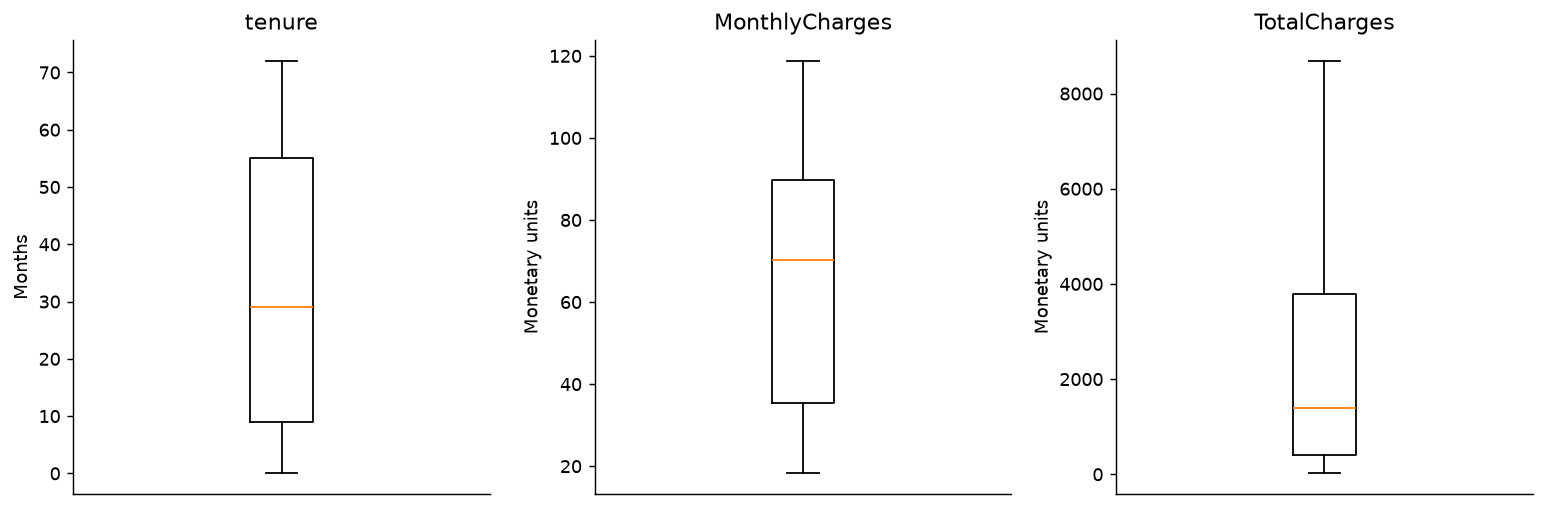

In [16]:
import matplotlib.pyplot as plt

numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, column in zip(axes, numerical_columns):
    values = df_clean[column].dropna().to_numpy(dtype=float)

    ax.boxplot(values)
    ax.set_title(column)
    ax.set_xticks([])
    ax.set_ylabel("Months" if column == "tenure" else "Monetary units")

plt.tight_layout()
plt.show()

The plots reveal no obvious values requiring further investigation. No records are removed; this visual assessment does not prove the absence of errors or imply normal distributions.

### 3.5 Final validation and preparation summary

Final checks verify that preparation preserved the customer records, retained unique identifiers, and converted `TotalCharges` to a numerical type without introducing unexpected missing values.

| Check or issue | Finding | Action |
|---|---|---|
| Dataset structure | Expected columns present | No correction required |
| Customer identifiers and duplicates | Identifiers present and unique; no duplicate rows | All records retained |
| Missing information | 11 blank `TotalCharges` entries, all with zero tenure | Represented as missing numerical values; no imputation |
| Numerical storage | `TotalCharges` initially stored as text | Converted to a numerical type |
| Categories and numerical ranges | No issues identified in the checks performed | No correction required |
| Service consistency | No mismatches detected | No correction required |
| Unusual numerical values | No obvious issues requiring investigation | No observations removed |

The raw dataframe remains unchanged. Model-specific preprocessing has not yet been applied.

In [17]:
from pandas.api.types import is_numeric_dtype

assert not missing_columns and not unexpected_columns and not duplicate_column_names
assert not missing_ids.any() and not blank_ids.any()
assert df_clean["customerID"].is_unique and not df_clean.duplicated().any()
assert df_clean.shape == df_raw.shape
assert is_numeric_dtype(df_clean["TotalCharges"])
assert (df_clean["TotalCharges"].isna() == missing_total_charges).all()
assert not consistency_flags.any().any()
assert not df_clean[numerical_columns].lt(0).any().any()
pd.testing.assert_frame_equal(
    df_clean.drop(columns="TotalCharges"), df_raw.drop(columns="TotalCharges")
)
print("Preparation validated: all customer records retained; only TotalCharges changed.")

Preparation validated: all customer records retained; only TotalCharges changed.


## 4. Analysis and validation design

The current analysis uses a training sample, reserving a test sample for the planned predictive extension.

### 4.1 Training and test sets

A reproducible, stratified 80/20 split preserves approximately the churn proportions in each sample. Training data support exploration, statistical comparisons, and later model development. Test data are used here only to verify size, balance, and customer separation.

Full-data summaries may be added after predictive evaluation. Prior dataset familiarity remains a limitation; reserving a test set does not undo earlier exposure.

In [18]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
    df_clean,
    test_size=0.20,
    stratify=df_clean["Churn"],
    random_state=42,
)

df_train = df_train.copy()
df_test = df_test.copy()

In [19]:
split_summary = pd.DataFrame({
    "Customers": [
        len(df_train),
        len(df_test),
    ],
    "Share of dataset (%)": [
        100 * len(df_train) / len(df_clean),
        100 * len(df_test) / len(df_clean),
    ],
    "Churn proportion (%)": [
        100 * df_train["Churn"].eq("Yes").mean(),
        100 * df_test["Churn"].eq("Yes").mean(),
    ],
}, index=["Training", "Test"])

display(split_summary.round(2))

,Customers,Share of dataset (%),Churn proportion (%)
Training,5634,79.99,26.54
Test,1409,20.01,26.54


In [20]:
train_ids = set(df_train["customerID"])
test_ids = set(df_test["customerID"])
all_ids = set(df_clean["customerID"])

assert train_ids.isdisjoint(test_ids), (
    "Some customers appear in both sets."
)

assert train_ids | test_ids == all_ids, (
    "The split does not cover all customers."
)

assert len(df_train) + len(df_test) == len(df_clean), (
    "The split changed the total number of records."
)

print("Split validation passed.")

Split validation passed.


### 4.2 Planned predictive evaluation

These are design decisions for future work, not completed evaluations. A constant-probability baseline will use churn prevalence estimated from training data, or separately within each training fold.

| Aspect | Assessment | Purpose |
|---|---|---|
| Ranking | ROC-AUC | Discrimination between recorded churn groups |
| Probability quality | Brier score | Mean squared probability error; lower is better |
| Calibration | Calibration plot | Agreement between predicted and observed frequencies |
| Classification | Confusion matrix, precision, recall, F1 | Performance at a stated threshold, with churn positive |

ROC-AUC and Brier score will be the main numerical summaries. Accuracy alone is insufficient when one outcome is more common. A threshold of 0.5 is a reference, not an assumed business optimum; any alternative must be selected using training data. Economic optimization would require intervention costs and effectiveness data.

### 4.3 Planned preprocessing and model selection

Logistic regression will be the primary model. Predictor inclusion will depend on meaning, training-set findings, redundancy, and functional form—not individual p-values alone. Structurally duplicated service indicators must be avoided.

Learned encoding, scaling, and any required imputation will be fitted inside training folds using a predictive pipeline. Only a small number of justified specifications will be compared by training-set cross-validation. The model and threshold will be fixed before test evaluation. Any revision prompted by test outcomes would require acknowledging reuse of that test set.

## 5. Exploratory data analysis

All results below use the 5,634-customer training set. Tables show counts and within-group churn proportions. Comparisons are unadjusted; the test set is not explored.

### 5.1 Overall churn

Establish the training-sample baseline before comparing subgroups.

In [21]:
churn_summary = (
    df_train["Churn"]
    .value_counts()
    .reindex(["No", "Yes"], fill_value=0)
    .rename_axis("Churn")
    .to_frame("Customers")
)

churn_summary["Percentage"] = (
    100 * churn_summary["Customers"] / len(df_train)
)

display(churn_summary.round(2))

,Customers,Percentage
Churn,,
No,4139,73.46
Yes,1495,26.54


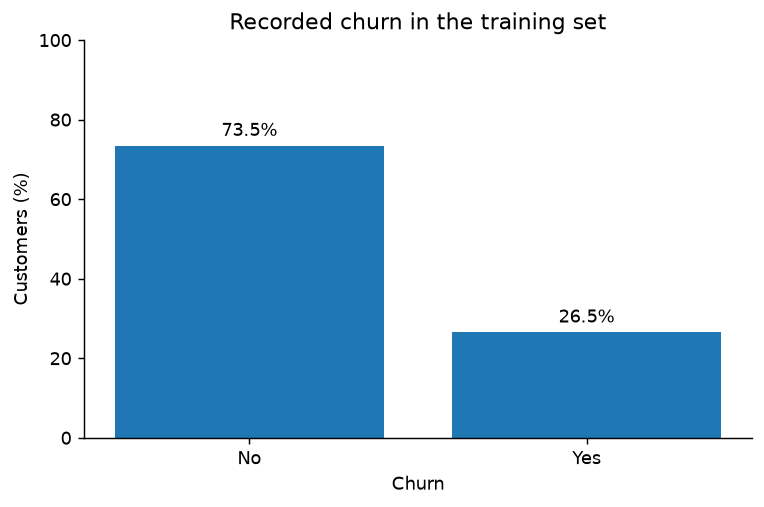

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    churn_summary.index,
    churn_summary["Percentage"],
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.set(
    title="Recorded churn in the training set",
    xlabel="Churn",
    ylabel="Customers (%)",
    ylim=(0, 100),
)

plt.tight_layout()
plt.show()

Recorded churn is 26.54% (1,495 of 5,634 customers). Predicting no churn for everyone would achieve 73.46% training accuracy while identifying none of the churned customers.

### 5.2 Contract type

Compare churn within each contract category, using that category's customer count as the denominator. The dashed line shows the overall training proportion.

In [23]:
contract_order = ["Month-to-month", "One year", "Two year"]

contract_summary = (
    df_train.groupby("Contract")["Churn"]
    .agg(
        Customers="size",
        Churned=lambda values: values.eq("Yes").sum(),
    )
    .reindex(contract_order)
)

contract_summary["Churn proportion (%)"] = (
    100 * contract_summary["Churned"] / contract_summary["Customers"]
)

display(contract_summary.round(2))

,Customers,Churned,Churn proportion (%)
Contract,,,
Month-to-month,3102,1326,42.75
One year,1173,130,11.08
Two year,1359,39,2.87


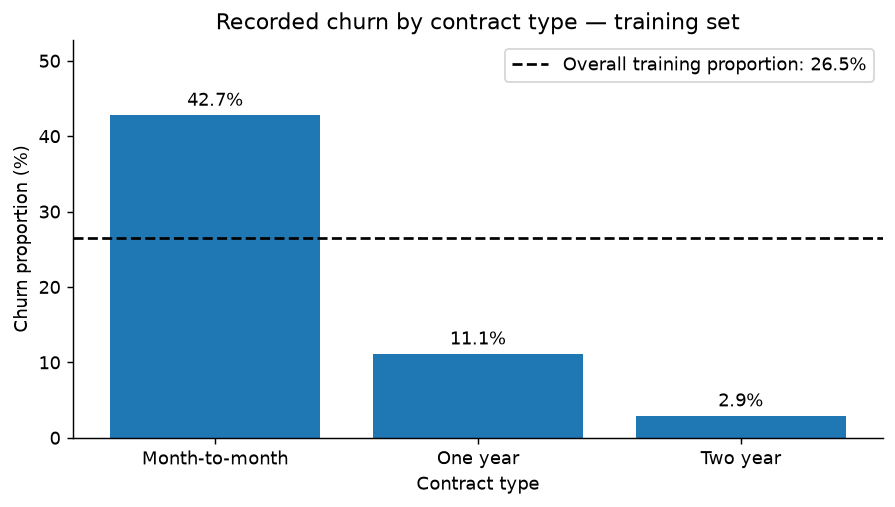

In [24]:
overall_churn_percentage = 100 * df_train["Churn"].eq("Yes").mean()

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    contract_summary.index,
    contract_summary["Churn proportion (%)"],
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.axhline(
    overall_churn_percentage,
    color="black",
    linestyle="--",
    label=f"Overall training proportion: {overall_churn_percentage:.1f}%",
)

ax.set(
    title="Recorded churn by contract type — training set",
    xlabel="Contract type",
    ylabel="Churn proportion (%)",
)

ax.set_ylim(
    0,
    max(
        contract_summary["Churn proportion (%)"].max(),
        overall_churn_percentage,
    ) + 10,
)

ax.legend()
plt.tight_layout()
plt.show()

Month-to-month churn is 42.75% (1,326/3,102), compared with 11.08% (130/1,173) for one-year and 2.87% (39/1,359) for two-year contracts. Contract groups may differ in tenure and other characteristics; these differences do not establish an effect of changing contracts.

### 5.3 Tenure

First compare tenure distributions within churn groups; then compare churn proportions within approximately yearly tenure bands. The two summaries condition on different variables and answer complementary questions.

In [25]:
tenure_summary = (
    df_train.groupby("Churn")["tenure"]
    .agg(
        Customers="count",
        Mean="mean",
        Median="median",
        SD="std",
        Q1=lambda values: values.quantile(0.25),
        Q3=lambda values: values.quantile(0.75),
        Minimum="min",
        Maximum="max",
    )
    .reindex(["No", "Yes"])
)

display(tenure_summary.round(2))

,Customers,Mean,Median,SD,Q1,Q3,Minimum,Maximum
Churn,,,,,,,,
No,4139,37.59,38.0,24.14,15.0,61.0,0,72
Yes,1495,18.36,10.0,19.74,2.0,29.0,1,72


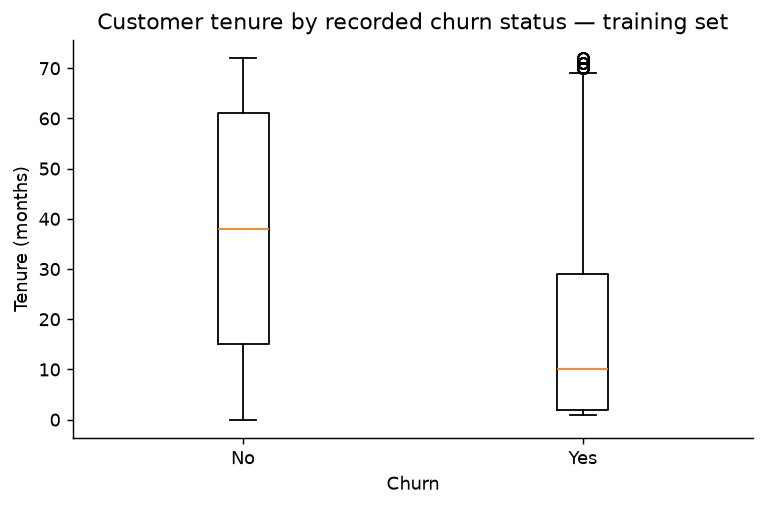

In [26]:
churn_order = ["No", "Yes"]

tenure_values = [
    df_train.loc[df_train["Churn"].eq(status), "tenure"]
    .dropna()
    .to_numpy(dtype=float)
    for status in churn_order
]

fig, ax = plt.subplots(figsize=(6, 4))

ax.boxplot(tenure_values)
ax.set_xticks([1, 2], churn_order)

ax.set(
    title="Customer tenure by recorded churn status — training set",
    xlabel="Churn",
    ylabel="Tenure (months)",
)

plt.tight_layout()
plt.show()

Mean tenure is 18.36 months for churned customers and 37.59 for non-churned customers; medians are 10 and 38 months. The middle 50% spans 2–29 versus 15–61 months. Distributions overlap and both reach 72 months.

Higher-tenure points beyond the churned group's whiskers are not necessarily errors. Next, descriptive bands retain every observed tenure value; tenure remains numerical for later modeling.

In [27]:
tenure_data = df_train[["tenure", "Churn"]].copy()

tenure_labels = [
    "0–12", "13–24", "25–36",
    "37–48", "49–60", "61–72",
]

tenure_data["Tenure group"] = pd.cut(
    tenure_data["tenure"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=tenure_labels,
    right=True,
)

assert tenure_data["Tenure group"].notna().all(), (
    "Some customers were not assigned to a tenure group."
)

tenure_group_summary = (
    tenure_data.groupby("Tenure group", observed=False)["Churn"]
    .agg(
        Customers="size",
        Churned=lambda values: values.eq("Yes").sum(),
    )
)

tenure_group_summary["Churn proportion (%)"] = (
    100
    * tenure_group_summary["Churned"]
    / tenure_group_summary["Customers"]
)

display(tenure_group_summary.round(2))

,Customers,Churned,Churn proportion (%)
Tenure group,,,
0–12,1737,822,47.32
13–24,818,234,28.61
25–36,669,140,20.93
37–48,621,121,19.48
49–60,658,101,15.35
61–72,1131,77,6.81


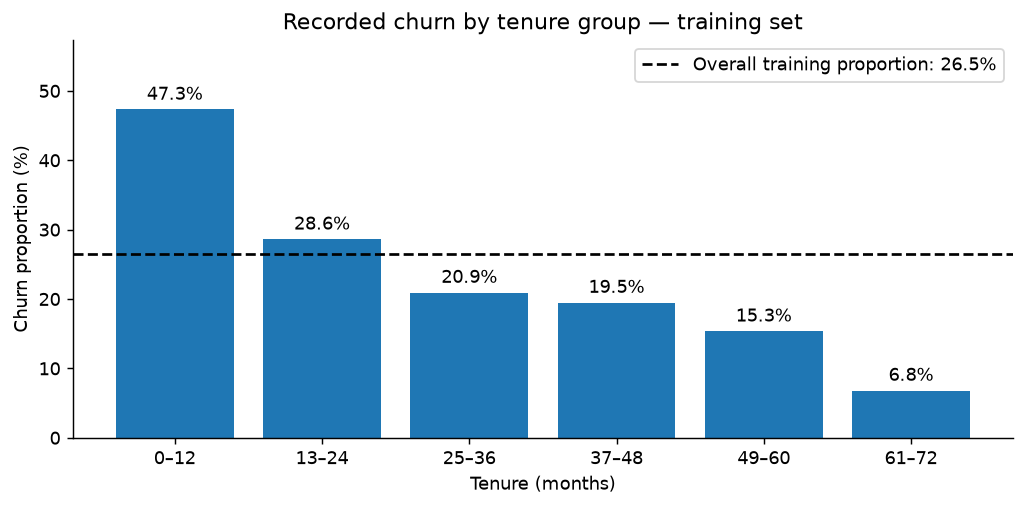

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    tenure_group_summary.index.astype(str),
    tenure_group_summary["Churn proportion (%)"],
)

ax.bar_label(bars, fmt="%.1f%%", padding=3)

ax.axhline(
    overall_churn_percentage,
    color="black",
    linestyle="--",
    label=f"Overall training proportion: {overall_churn_percentage:.1f}%",
)

ax.set(
    title="Recorded churn by tenure group — training set",
    xlabel="Tenure (months)",
    ylabel="Churn proportion (%)",
)

ax.set_ylim(
    0,
    max(
        tenure_group_summary["Churn proportion (%)"].max(),
        overall_churn_percentage,
    ) + 10,
)

ax.legend()
plt.tight_layout()
plt.show()

Churn proportions decrease from 47.32% (822/1,737) at 0–12 months to 6.81% (77/1,131) at 61–72 months. These compare different customers in a snapshot; they do not describe how an individual's future churn risk changes over time.

In [29]:
def summarize_churn(frame, feature):
    """Counts and within-group proportions; no inferential claims."""
    result = frame.groupby(feature, observed=True, dropna=False)["Churn"].agg(
        Customers="size", Churned=lambda values: values.eq("Yes").sum()
    )
    result["Churn proportion (%)"] = 100 * result["Churned"] / result["Customers"]
    return result




### 5.4 Contract and tenure together

Compare tenure composition across contracts and contract-specific churn within broad tenure bands. Counts accompany proportions because sparse event counts make some cells uncertain. Broad bands do not fully adjust for continuous tenure.

,Customers,Mean,Median
Contract,,,
Month-to-month,3102,18.13,12.0
One year,1173,42.44,44.0
Two year,1359,56.65,64.0


Customers  Churned  Churn proportion (%)
Tenure_group Contract                                                
0–12         Month-to-month       1594      814                 51.07
             One year               88        8                  9.09
             Two year               55        0                  0.00
13–24        Month-to-month        580      222                 38.28
             One year              166       12                  7.23
             Two year               72        0                  0.00
25–36        Month-to-month        396      123                 31.06
             One year              191       15                  7.85
             Two year               82        2                  2.44
37–48        Month-to-month        254       90                 35.43
             One year              222       29                 13.06
             Two year              145        2                  1.38
49–60        Month-to-month        190       56                 29.47
             One year              253       36                 14.23
             Two year              215        9                  4.19
61–72        Month-to-month         88       21                 23.86
             One year              253       30                 11.86
             Two year              790       26                  3.29

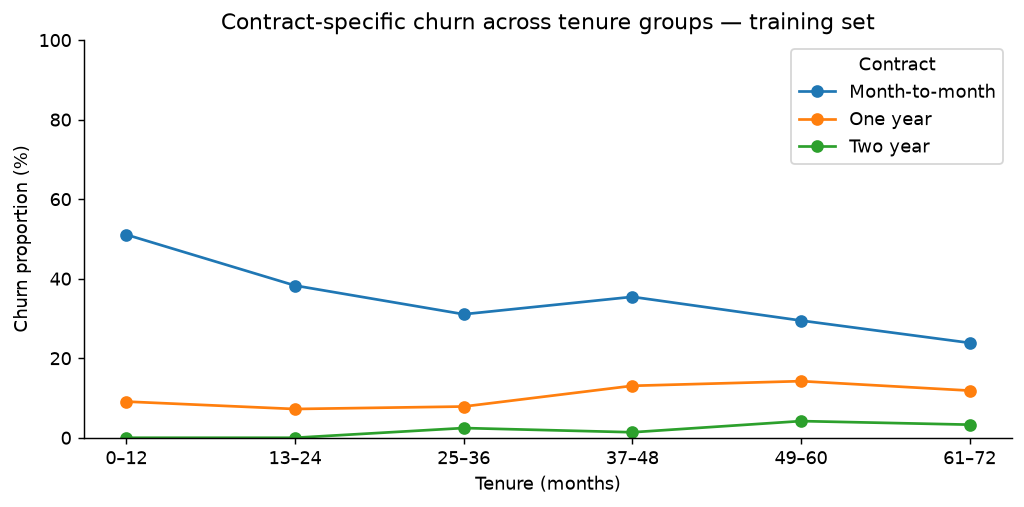

In [30]:
contract_order = ["Month-to-month", "One year", "Two year"]
contract_tenure = df_train.groupby("Contract")["tenure"].agg(
    Customers="size", Mean="mean", Median="median"
).reindex(contract_order)
display(contract_tenure.round(2))
joint = df_train.assign(Tenure_group=pd.cut(
    df_train["tenure"], bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=["0–12", "13–24", "25–36", "37–48", "49–60", "61–72"]
))
joint_summary = joint.groupby(["Tenure_group", "Contract"], observed=True)["Churn"].agg(
    Customers="size", Churned=lambda values: values.eq("Yes").sum()
)
joint_summary["Churn proportion (%)"] = 100 * joint_summary["Churned"] / joint_summary["Customers"]
assert joint_summary["Customers"].sum() == len(df_train)
display(joint_summary.round(2))
rates = joint_summary["Churn proportion (%)"].unstack("Contract").reindex(columns=contract_order)
ax = rates.plot(marker="o", figsize=(8, 4))
ax.set(xlabel="Tenure (months)", ylabel="Churn proportion (%)",
       title="Contract-specific churn across tenure groups — training set", ylim=(0, 100))
ax.legend(title="Contract")
plt.tight_layout()
plt.show()


Mean tenure is 18.1 months for month-to-month customers, 42.4 for one-year, and 56.7 for two-year contracts. Month-to-month customers have the highest churn proportion in every displayed tenure band. Broad stratification does not remove the pattern, but it does not establish causality or fully adjust for tenure. Some cells have no churn events; these do not imply zero risk.

### 5.5 Monthly charges

Compare charge distributions by churn and churn proportions within training-derived charge quintiles. Quintiles are descriptive, not proposed model inputs.

,Customers,Mean,Median,Q1,Q3
Churn,,,,,
No,4139,61.34,64.40,25.15,88.18
Yes,1495,74.86,79.95,56.90,94.40


,Customers,Churned,Churn proportion (%)
Monthly-charge group,,,
"(18.39, 25.10]",1134,103,9.08
"(25.10, 59.00]",1121,276,24.62
"(59.00, 79.30]",1126,329,29.22
"(79.30, 94.45]",1133,419,36.98
"(94.45, 118.75]",1120,368,32.86


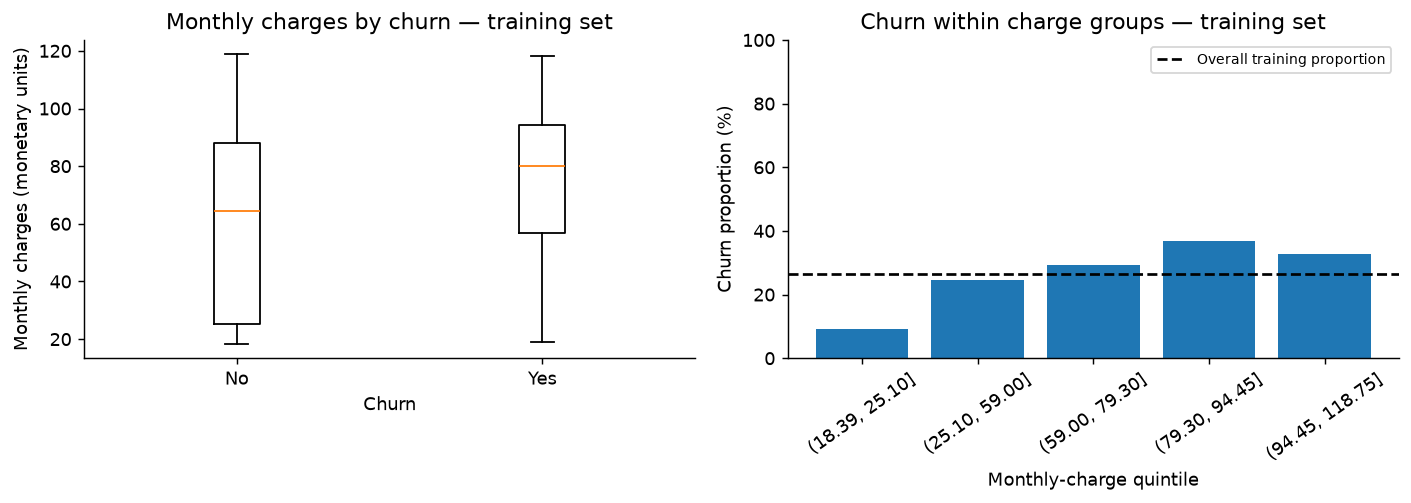

In [31]:
charge_summary = df_train.groupby("Churn")["MonthlyCharges"].agg(
    Customers="count", Mean="mean", Median="median",
    Q1=lambda values: values.quantile(.25), Q3=lambda values: values.quantile(.75)
).reindex(["No", "Yes"])
display(charge_summary.round(2))
charge_data = df_train.assign(Charge_group=pd.qcut(df_train["MonthlyCharges"], 5, precision=2, duplicates="drop"))
charge_groups = summarize_churn(charge_data, "Charge_group")
charge_groups.index = pd.Index([f"({band.left:.2f}, {band.right:.2f}]" for band in charge_groups.index], name="Monthly-charge group")
display(charge_groups.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].boxplot([df_train.loc[df_train["Churn"].eq(s), "MonthlyCharges"].to_numpy() for s in ["No", "Yes"]])
axes[0].set_xticks([1, 2], ["No", "Yes"])
axes[0].set(xlabel="Churn", ylabel="Monthly charges (monetary units)", title="Monthly charges by churn — training set")
axes[1].bar(charge_groups.index.astype(str), charge_groups["Churn proportion (%)"])
axes[1].axhline(overall_churn_percentage, color="black", linestyle="--", label="Overall training proportion")
axes[1].tick_params(axis="x", rotation=35)
axes[1].set(xlabel="Monthly-charge quintile", ylabel="Churn proportion (%)", title="Churn within charge groups — training set", ylim=(0, 100))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


Churned customers have higher mean monthly charges (74.86 versus 61.34) and medians (79.95 versus 64.40). Churn proportions rise across the first four quintiles and fall in the highest. This does not establish a linear conditional relationship; service mix may contribute.

### 5.6 Services and billing

Compare internet add-ons only among internet subscribers, and multiple lines only among telephone subscribers. This separates absence of the underlying service from absence of an add-on. The table names each comparison population; service mix and other correlated attributes remain possible explanations.

,Variable,Population,Category,Customers,Churned,Churn proportion (%)
0,InternetService,All training customers,DSL,1937,362,18.69
1,InternetService,All training customers,Fiber optic,2483,1045,42.09
2,InternetService,All training customers,No,1214,88,7.25
3,PhoneService,All training customers,No,559,135,24.15
4,PhoneService,All training customers,Yes,5075,1360,26.80
5,MultipleLines,Telephone subscribers,No,2685,672,25.03
6,MultipleLines,Telephone subscribers,Yes,2390,688,28.79
7,OnlineSecurity,Internet subscribers,No,2797,1173,41.94
8,OnlineSecurity,Internet subscribers,Yes,1623,234,14.42
9,OnlineBackup,Internet subscribers,No,2442,980,40.13


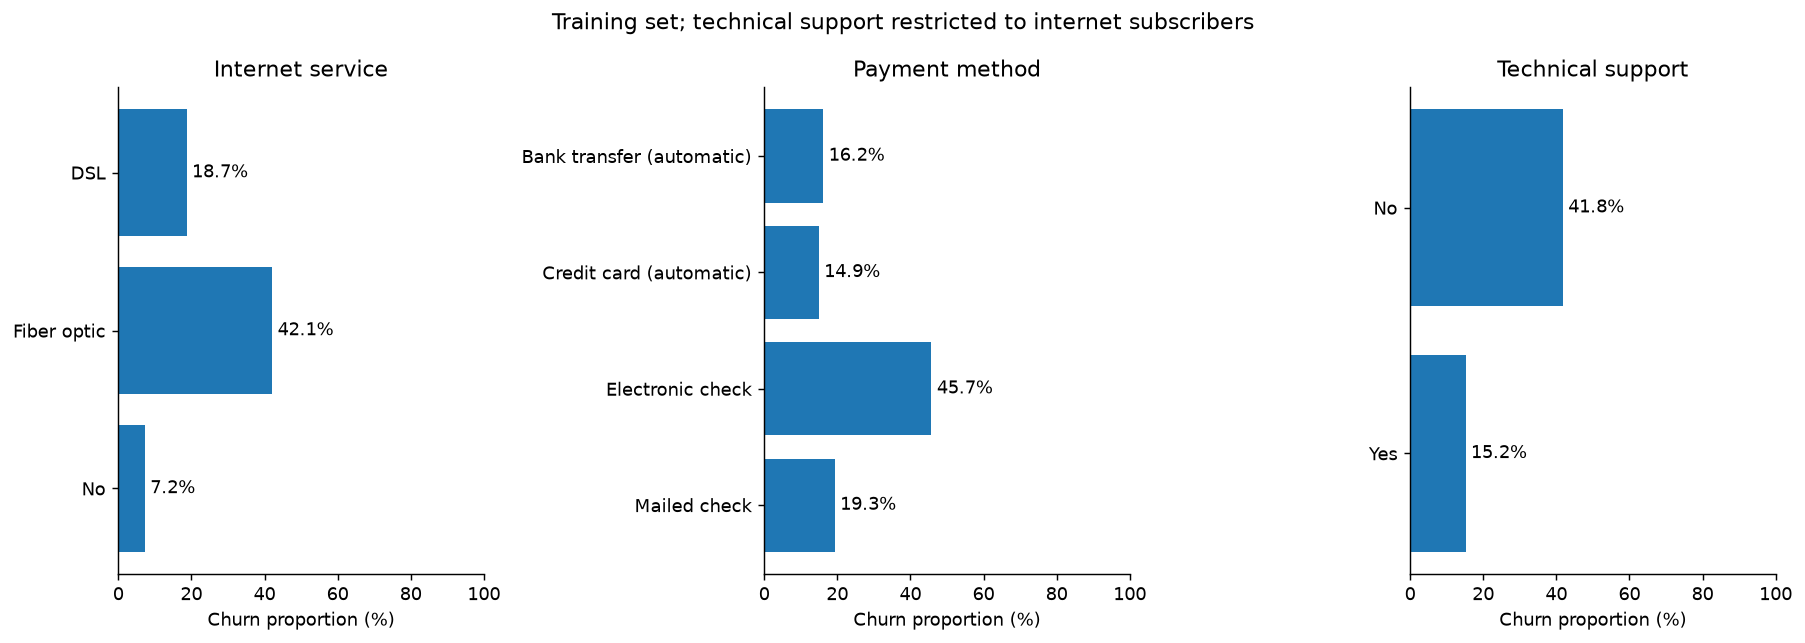

In [32]:
service_features = ["InternetService", "PhoneService", "MultipleLines", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
    "PaperlessBilling", "PaymentMethod"]
internet_addons = {"OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"}
service_tables = []
for feature in service_features:
    frame = df_train
    population = "All training customers"
    if feature in internet_addons:
        frame = df_train.loc[df_train["InternetService"].ne("No")]
        population = "Internet subscribers"
    elif feature == "MultipleLines":
        frame = df_train.loc[df_train["PhoneService"].eq("Yes")]
        population = "Telephone subscribers"
    table = summarize_churn(frame, feature).rename_axis("Category").reset_index()
    assert table["Customers"].sum() == len(frame)
    table.insert(0, "Variable", feature)
    table.insert(1, "Population", population)
    service_tables.append(table)
service_summary = pd.concat(service_tables, ignore_index=True)
display(service_summary.round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, feature in zip(axes, ["InternetService", "PaymentMethod", "TechSupport"]):
    table = service_summary.loc[service_summary["Variable"].eq(feature)]
    bars = ax.barh(table["Category"].astype(str), table["Churn proportion (%)"])
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set(xlim=(0, 100), xlabel="Churn proportion (%)", title={"InternetService": "Internet service", "PaymentMethod": "Payment method", "TechSupport": "Technical support"}[feature])
    ax.invert_yaxis()
fig.suptitle("Training set; technical support restricted to internet subscribers")
plt.tight_layout()
plt.show()


Recorded churn is 42.09% for fiber optic, 18.69% for DSL, and 7.25% without internet. Electronic-check customers show 45.74% churn. Among internet subscribers, churn is 41.75% without technical support versus 15.16% with support. These are unadjusted group differences, not estimated effects of services or payment methods.

### 5.7 Customer and household characteristics

Summarize recorded gender, senior status, partner status, and dependents. Senior-status codes are labeled for readability. These group comparisons do not identify causal mechanisms.

In [33]:
demographic_data = df_train.assign(
    SeniorCitizen=df_train["SeniorCitizen"].map({0: "No", 1: "Yes"})
)
demographic_tables = []
for feature in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    table = summarize_churn(demographic_data, feature).rename_axis("Category").reset_index()
    table.insert(0, "Variable", feature)
    demographic_tables.append(table)
demographic_summary = pd.concat(demographic_tables, ignore_index=True)
display(demographic_summary.round(2))


,Variable,Category,Customers,Churned,Churn proportion (%)
0,gender,Female,2801,746,26.63
1,gender,Male,2833,749,26.44
2,SeniorCitizen,No,4714,1117,23.70
3,SeniorCitizen,Yes,920,378,41.09
4,Partner,No,2905,952,32.77
5,Partner,Yes,2729,543,19.90
6,Dependents,No,3955,1240,31.35
7,Dependents,Yes,1679,255,15.19


Recorded gender groups have similar churn proportions (26.63% versus 26.44%). Higher proportions are observed for senior customers (41.09% versus 23.70%), customers without partners (32.77% versus 19.90%), and those without dependents (31.35% versus 15.19%). Other account characteristics may contribute.

### 5.8 Exploratory synthesis

Contract, tenure, charges, and several service and billing attributes show patterns worth considering jointly. The descriptive tables guide focused comparisons rather than automatic predictor selection. `TotalCharges` is not given a separate churn chart because its accumulation over tenure makes a standalone comparison difficult to interpret.

## 6. Selected statistical comparisons

Quantify contract differences and the mean tenure difference, emphasizing magnitude and uncertainty. These questions were selected after exploration; intervals and p-values do not account for that selection or multiple comparisons.

**Inferential scope:** The calculations assume independent customer observations from a hypothetical sampling process. The fictional dataset does not establish that process, and the standard intervals do not explicitly account for the stratified split. Treat them as illustrative model-based uncertainty, not evidence about real telecom populations. For these observed records, the descriptive values themselves are known.

### 6.1 Contract and churn

#### Individual proportions

Report 95% Wilson intervals, which generally behave better than simple normal-approximation intervals near zero or one. These are individual rather than simultaneous intervals.

In [34]:
import numpy as np
import scipy
import statsmodels
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import (
    proportion_confint,
    confint_proportions_2indep,
)
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW

print(f"SciPy {scipy.__version__} | statsmodels {statsmodels.__version__}")
contract_order = ["Month-to-month", "One year", "Two year"]
contract_inference = (
    df_train.groupby("Contract")["Churn"]
    .agg(Customers="size", Churned=lambda values: values.eq("Yes").sum())
    .reindex(contract_order)
)
contract_inference["Churn proportion (%)"] = (
    100 * contract_inference["Churned"] / contract_inference["Customers"]
)
lower, upper = proportion_confint(
    count=contract_inference["Churned"],
    nobs=contract_inference["Customers"],
    alpha=0.05,
    method="wilson",
)
contract_inference["95% CI lower (%)"] = 100 * lower
contract_inference["95% CI upper (%)"] = 100 * upper
display(contract_inference.round(2))

SciPy 1.18.1 | statsmodels 0.15.0


,Customers,Churned,Churn proportion (%),95% CI lower (%),95% CI upper (%)
Contract,,,,,
Month-to-month,3102,1326,42.75,41.02,44.50
One year,1173,130,11.08,9.41,13.01
Two year,1359,39,2.87,2.11,3.90


#### Differences in proportions

Compare month-to-month minus each longer contract, in percentage points. Newcombe intervals combine Wilson intervals for independent proportions. Each interval has nominal 95% coverage, without multiplicity adjustment.

In [35]:
reference = contract_inference.loc["Month-to-month"]
comparison_rows = []
for contract in ["One year", "Two year"]:
    comparison = contract_inference.loc[contract]
    count1, nobs1 = int(reference["Churned"]), int(reference["Customers"])
    count2, nobs2 = int(comparison["Churned"]), int(comparison["Customers"])
    lower, upper = confint_proportions_2indep(
        count1=count1, nobs1=nobs1,
        count2=count2, nobs2=nobs2,
        compare="diff", method="newcomb", alpha=0.05,
    )
    comparison_rows.append({
        "Comparison": f"Month-to-month minus {contract.lower()}",
        "Difference (pp)": 100 * (count1 / nobs1 - count2 / nobs2),
        "95% CI lower (pp)": 100 * lower,
        "95% CI upper (pp)": 100 * upper,
    })
contract_differences = pd.DataFrame(comparison_rows).set_index("Comparison")
display(contract_differences.round(2))

,Difference (pp),95% CI lower (pp),95% CI upper (pp)
Comparison,,,
Month-to-month minus one year,31.66,29.08,34.08
Month-to-month minus two year,39.88,37.86,41.79


#### Overall association

Pearson's chi-square test evaluates independence of contract and churn. Expected counts assess sparse-cell concerns, not independence between customer records. Cramér's V summarizes association strength without direction; the percentage-point contrasts are more directly interpretable.

In [36]:
contract_contingency = pd.crosstab(
    df_train["Contract"], df_train["Churn"]
).reindex(index=contract_order, columns=["No", "Yes"])
assert contract_contingency.to_numpy().sum() == len(df_train)
display(contract_contingency)

chi2, contract_p_value, degrees_of_freedom, expected = chi2_contingency(
    contract_contingency, correction=False
)
expected_counts = pd.DataFrame(
    expected, index=contract_contingency.index, columns=contract_contingency.columns
)
display(expected_counts.round(2))
n_customers = int(contract_contingency.to_numpy().sum())
cramers_v = np.sqrt(
    chi2 / (n_customers * min(contract_contingency.shape[0] - 1,
                              contract_contingency.shape[1] - 1))
)
print(f"Pearson chi-square: {chi2:.2f}")
print(f"Degrees of freedom: {degrees_of_freedom}")
print(f"p-value: {contract_p_value:.3g}")
print(f"Cramér's V: {cramers_v:.3f}")
print(f"Smallest expected count: {expected.min():.2f}")

Pearson chi-square: 952.31
Degrees of freedom: 2
p-value: 1.62e-207
Cramér's V: 0.411
Smallest expected count: 311.26


Churn,No,Yes
Contract,,
Month-to-month,1776,1326
One year,1043,130
Two year,1320,39


Churn,No,Yes
Contract,,
Month-to-month,2278.87,823.13
One year,861.74,311.26
Two year,998.38,360.62


### 6.2 Mean tenure difference

Estimate churned minus non-churned mean tenure. Welch's interval and two-sided test allow unequal variances. Both groups are large and tenure is bounded, supporting a large-sample approximation despite skewness. Chapter 5's medians and plots remain distributional context; the mean difference does not summarize the entire distribution.

In [37]:
tenure_churned = df_train.loc[df_train["Churn"].eq("Yes"), "tenure"].dropna().to_numpy(dtype=float)
tenure_not_churned = df_train.loc[df_train["Churn"].eq("No"), "tenure"].dropna().to_numpy(dtype=float)

tenure_comparison = CompareMeans(
    DescrStatsW(tenure_churned), DescrStatsW(tenure_not_churned)
)
tenure_difference = tenure_churned.mean() - tenure_not_churned.mean()
tenure_ci_lower, tenure_ci_upper = tenure_comparison.tconfint_diff(
    alpha=0.05, alternative="two-sided", usevar="unequal"
)
welch_t, tenure_p_value, welch_df = tenure_comparison.ttest_ind(
    alternative="two-sided", usevar="unequal"
)
tenure_inference = pd.DataFrame([{
    "Churned customers": len(tenure_churned),
    "Non-churned customers": len(tenure_not_churned),
    "Mean tenure: churned (months)": tenure_churned.mean(),
    "Mean tenure: non-churned (months)": tenure_not_churned.mean(),
    "Mean difference (months)": tenure_difference,
    "95% CI lower (months)": tenure_ci_lower,
    "95% CI upper (months)": tenure_ci_upper,
}])
display(tenure_inference.T.round(2).rename(columns={0: "Estimate"}))
print(f"Welch t: {welch_t:.2f}; degrees of freedom: {welch_df:.2f}")
print(f"Two-sided p-value: {tenure_p_value:.3g}")

Welch t: -30.35; degrees of freedom: 3206.98
Two-sided p-value: 4.44e-178


,Estimate
Churned customers,1495.00
Non-churned customers,4139.00
Mean tenure: churned (months),18.36
Mean tenure: non-churned (months),37.59
Mean difference (months),-19.23
95% CI lower (months),-20.47
95% CI upper (months),-17.99


### 6.3 Interpretation

Month-to-month churn exceeds one-year churn by **31.66 percentage points** (95% CI 29.08–34.08) and two-year churn by **39.88 points** (37.86–41.79).

The overall contract association has χ²(2) = **952.31**, p < 0.001, and Cramér's V = **0.411**. The minimum expected cell count is 311.26, with no sparse-cell concern. Small p-values do not measure importance or establish causality.

Mean tenure is **19.23 months shorter** among churned customers (churned minus non-churned: −19.23; 95% CI −20.47 to −17.99; Welch p < 0.001). This is a between-group comparison, not a trajectory over time.

Contract groups differ in tenure composition, so these unadjusted findings cannot attribute the contract pattern independently of tenure or other attributes. Conditional associations require the planned multivariable analysis.

## 7. Current conclusions, limitations, and next steps

### Findings and business relevance

Recorded churn is concentrated among month-to-month and shorter-tenure customers. The contract pattern persists within broad tenure bands, and selected service and billing groups also differ. These patterns can prioritize questions about onboarding, service experience, and account arrangements; they do not establish which intervention would retain a customer.

### Limitations

- Fictional observational data with an uncertain sampling process limit population inference and generalization.
- Attribute timing is unclear; these results concern recorded status rather than future churn forecasting.
- Comparisons are exploratory and unadjusted. Reported intervals omit selection, multiplicity, and explicit split-design adjustments.
- Subgroup counts differ, and zero events do not imply zero underlying risk.
- Prior exposure to the dataset limits independence of future predictive evaluation.

### Planned extensions

Fit an interpretable logistic regression with justified predictor representation, assess nonlinearity and estimate stability, then evaluate a fixed predictive pipeline against the baseline on reserved test data. These extensions are not required to reproduce the current release.